<a href="https://colab.research.google.com/github/Balice9/beginning-bioinformatics/blob/main/single_cell_pbmc3k_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
!pip install -q scanpy
import scanpy as sc
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

sc.settings.verbosity = 3
sc.logging.print_header()
sc.settings.set_figure_params(dpi=80, facecolor='white')

/tmp/ipykernel_2262/2519922232.py:12: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=80, facecolor='white')


In [16]:
print("Loading pbmc3k dataset...")
adata = sc.datasets.pbmc3k()

print("\n--- Initial State Verification ---")
print(f"Dataset shape (Cells x Genes): {adata.shape}")
print(f"Is adata.X sparse? {sp.issparse(adata.X)}")
print(f"Matrix data type: {type(adata.X)}")
print(f"Minimum value in adata.X: {adata.X.min()}")
print(f"Maximum value in adata.X: {adata.X.max()}")
print(f"Are values integers (raw counts)? {np.all(adata.X.data == adata.X.data.astype(int))}")

Loading pbmc3k dataset...

--- Initial State Verification ---
Dataset shape (Cells x Genes): (2700, 32738)
Is adata.X sparse? True
Matrix data type: <class 'scipy.sparse._csr.csr_matrix'>
Minimum value in adata.X: 0.0
Maximum value in adata.X: 419.0
Are values integers (raw counts)? True


In [12]:
print("\nRunning QC filtering...")
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

adata.var['mt'] = adata.var_names.str.startswith('MT-')
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)

adata = adata[adata.obs['pct_counts_mt'] < 5, :]
adata = adata[adata.obs['n_genes_by_counts'] < 2500, :]
print(f"Shape after QC filtering: {adata.shape}")

print("Normalizing counts and applying log1p transformation...")
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Save log-normalized data to .raw AFTER log1p (fixes the rank_genes_groups warning!)
adata.raw = adata

print("Identifying Highly Variable Genes...")
sc.pp.highly_variable_genes(adata, n_top_genes=1838)

sc.pp.regress_out(adata, ['total_counts', 'pct_counts_mt'])
sc.pp.scale(adata, max_value=10)


Running QC filtering...
filtered out 19024 genes that are detected in less than 3 cells
Shape after QC filtering: (2638, 13714)
Normalizing counts and applying log1p transformation...
normalizing counts per cell


/tmp/ipykernel_2262/4162990497.py:6: FutureWarning: The argument inplace is deprecated and will be removed in the future. Use `out=False` instead of `inplace=True`.
  sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
/usr/local/lib/python3.13/dist-packages/scverse_misc/_deprecated/__init__.py:117: UserWarning: Received a view of an AnnData. Making a copy.
  return func(*args, **kwargs)


    finished (0:00:00)
Identifying Highly Variable Genes...
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
regressing out ['total_counts', 'pct_counts_mt']
    sparse input is densified and may lead to high memory use
    finished (0:00:00)


In [13]:
print("\nPerforming PCA dimensionality reduction...")
sc.tl.pca(adata, n_comps=30, svd_solver='arpack')


Performing PCA dimensionality reduction...
computing PCA
    with n_comps=30
    finished (0:00:01)


In [14]:
pc_list = [10, 15, 20]
k_list = [4, 5, 6, 7, 8, 9, 10]
grid_results = []

print("\nExecuting K-Means parameter grid search...")
for n_pcs in pc_list:
    pca_coords = adata.obsm['X_pca'][:, :n_pcs]
    for k in k_list:
        kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
        cluster_labels = kmeans.fit_predict(pca_coords)
        sil_score = silhouette_score(pca_coords, cluster_labels, sample_size=1000, random_state=42)
        inertia = kmeans.inertia_
        grid_results.append({
            'n_pcs': n_pcs,
            'k': k,
            'silhouette_score': sil_score,
            'inertia': inertia
        })
        print(f"n_PCs: {n_pcs:2d} | k: {k:2d} | Silhouette Score: {sil_score:.4f} | Inertia: {inertia:,.2f}")

results_df = pd.DataFrame(grid_results)
display(results_df.sort_values(by='silhouette_score', ascending=False).head(10))


Executing K-Means parameter grid search...
n_PCs: 10 | k:  4 | Silhouette Score: 0.4193 | Inertia: 118,538.66
n_PCs: 10 | k:  5 | Silhouette Score: 0.4680 | Inertia: 85,725.84
n_PCs: 10 | k:  6 | Silhouette Score: 0.4058 | Inertia: 76,366.51
n_PCs: 10 | k:  7 | Silhouette Score: 0.3804 | Inertia: 67,417.16
n_PCs: 10 | k:  8 | Silhouette Score: 0.2635 | Inertia: 63,545.33
n_PCs: 10 | k:  9 | Silhouette Score: 0.2619 | Inertia: 60,796.46
n_PCs: 10 | k: 10 | Silhouette Score: 0.2687 | Inertia: 57,316.17
n_PCs: 15 | k:  4 | Silhouette Score: 0.3529 | Inertia: 156,380.61
n_PCs: 15 | k:  5 | Silhouette Score: 0.3894 | Inertia: 123,541.18
n_PCs: 15 | k:  6 | Silhouette Score: 0.3236 | Inertia: 114,149.73
n_PCs: 15 | k:  7 | Silhouette Score: 0.2925 | Inertia: 105,181.88
n_PCs: 15 | k:  8 | Silhouette Score: 0.1915 | Inertia: 101,113.45
n_PCs: 15 | k:  9 | Silhouette Score: 0.1975 | Inertia: 97,337.72
n_PCs: 15 | k: 10 | Silhouette Score: 0.1946 | Inertia: 94,156.42
n_PCs: 20 | k:  4 | Silhou

,n_pcs,k,silhouette_score,inertia
1,10,5,0.468005,85725.835938
0,10,4,0.419321,118538.656250
2,10,6,0.405841,76366.507812
8,15,5,0.389352,123541.179688
3,10,7,0.380403,67417.156250
7,15,4,0.352921,156380.609375
15,20,5,0.336462,160350.859375
9,15,6,0.323589,114149.734375
14,20,4,0.307487,193201.078125
10,15,7,0.292461,105181.882812



Generating UMAP and running differential expression...
computing neighbors
    using 'X_pca' with n_pcs = 15
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:07)


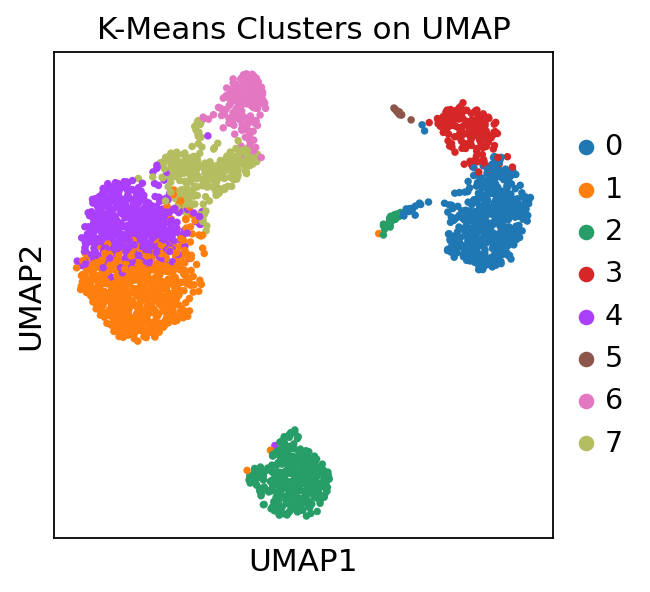

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:06)


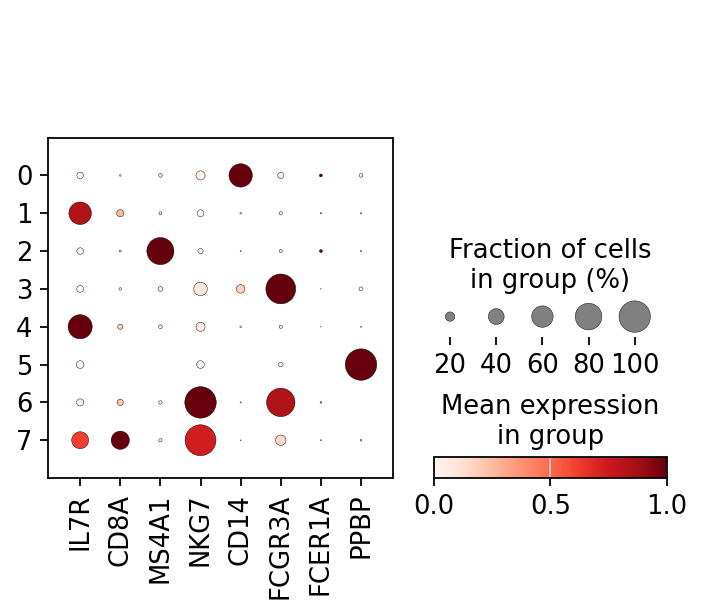

In [15]:
print("\nGenerating UMAP and running differential expression...")
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=15)
sc.tl.umap(adata)

optimal_kmeans = KMeans(n_clusters=8, init='k-means++', random_state=42, n_init=10).fit(adata.obsm['X_pca'][:, :15])
adata.obs['kmeans_cluster'] = optimal_kmeans.labels_.astype(str)

sc.pl.umap(adata, color=['kmeans_cluster'], title='K-Means Clusters on UMAP')


sc.tl.rank_genes_groups(adata, groupby='kmeans_cluster', method='wilcoxon')

canonical_markers = {
    'CD4+ T cells': 'IL7R',
    'CD8+ T cells': 'CD8A',
    'B cells': 'MS4A1',
    'NK cells': 'NKG7',
    'CD14+ Monocytes': 'CD14',
    'FCGR3A+ Monocytes': 'FCGR3A',
    'Dendritic Cells': 'FCER1A',
    'Platelets': 'PPBP'
}


sc.pl.dotplot(adata, list(canonical_markers.values()), groupby='kmeans_cluster', standard_scale='var')